# Active Subspaces of Airfoil Shape Parameterizations: Transonic Lift and Drag with PARSEC and CST

__Zachary J. Grey__, Aerospace Engineering Sciences Department, University of Colorado, Boulder, Colorado (now Rolls-Royce Corporation, Indianapolis, Indiana)

__Paul G. Constantine__, Department of Computer Science, University of Colorado, Boulder, Colorado

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook analyzes the SU2 runs behind Grey and Constantine [[1]][R1], which the authors posted in the [zgrey/ASAP](https://github.com/zgrey/ASAP) repository. Page, table and figure numbers refer to the published AIAA Journal article. It runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes one to three minutes.

**How it differs from [NACA0012_Airfoil](../NACA0012_Airfoil/).** Both data sets are SU2 runs on perturbed NACA 0012 airfoils. NACA0012_Airfoil perturbs the airfoil with 18 local Hicks–Henne bumps and has adjoint gradients, so its subspace comes from gradients. This one uses two *global* shape parameterizations, PARSEC (11 parameters with geometric meaning) and the class-shape transformation CST (10 polynomial coefficients), at stated flow conditions (inviscid, Mach 0.8, angle of attack 0°). It has values only, so the subspaces come from a global quadratic fit. Its question is how the choice of parameterization changes the active subspaces of lift and drag.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
from active_subspaces.subspaces import EVG
import convert_data as cd

SEED = 2018                       # the only seed in this notebook (bootstrap and subsampling)
t_start = time.perf_counter()

### Summary

Grey and Constantine [[1]][R1] perturb a NACA 0012 airfoil by ±20 % in the parameters of two shape parameterizations, PARSEC ($m = 11$) and CST ($m = 10$), and compute the lift and drag coefficients $C_l$ and $C_d$ with SU2's Euler solver at Mach 0.8. From the posted runs (6472 PARSEC and 6500 CST designs, with inputs regenerated from the authors' recorded random seeds) and a global least-squares quadratic, we find a one-dimensional active subspace for lift and a two-dimensional one for drag under both parameterizations, with eigenvalues, eigenvectors and subspace errors that match the paper's Figs. 3–5 and 8–10. Under CST, lift and drag depend only on the two leading coefficients $x_1$ and $x_6$, and the lift direction lies in the drag subspace, as the paper reports; PARSEC spreads the same structure over 7–8 of its 11 parameters.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*, which the paper calls a *shadow plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. When only values of $f$ are available, $\nabla f$ is replaced by the gradient of a fitted model, here a global quadratic, and the estimate is assessed with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Shapes.** Each airfoil surface (upper $s_U$, lower $s_L$) on the chord coordinate $l\in[0, 1]$ is a series in half-integer powers of $l$.

- **PARSEC** (Sobieczky [[2]][R2]; Sec. II.D): $s(l) = \sum_{j=1}^{6} a_j\, l^{\,j-1/2}$ for each surface. The 12 coefficients solve a linear system $\mathbf M(x_1, x_2)\,\mathbf a = \mathbf p(\mathbf x)$ (Eq. 10) whose equations fix 11 geometric characteristics (Table 1, p. 2005): the crest positions $x_1, x_2$ and heights $x_3, x_4$ of the upper and lower surfaces, the trailing-edge offset $x_5$ and half-thickness $x_6$, the wedge angle $x_7$ and half-angle $x_8$, the crest curvatures ("inflections") $x_9, x_{10}$, and the leading-edge radius $x_{11}$.
- **CST** (Kulfan [[3]][R3]; Sec. II.E): $s(l) = l^{1/2}(1-l)\sum_{j=0}^{4} x_j\, l^{\,j}$ for each surface (Eqs. 11–13 with $r_1 = 1/2$, $r_2 = 1$, $m = 5$ per surface), so $m = 10$; the paper numbers the upper-surface coefficients $x_1$–$x_5$ and the lower ones $x_6$–$x_{10}$ (p. 2011). The class function gives a round nose and a sharp trailing edge.

**Inputs and density.** For each parameterization the authors fit the parameters to a NACA 0012 by nonlinear least squares and set bounds at ±20 % of the fitted values; $\rho$ is uniform on the resulting box (Sec. IV, p. 2008). The tables below print the bounds of Tables 2 and 3 as published. The posted data, and this notebook, use the authors' **normalized** design variables, $x_j\in[-1, 1]$ (`2*rand(N, m) - 1` in their MATLAB scripts), which is also the coordinate system of the paper's eigenvectors. The physical values follow only approximately (`DATA.md`, "Physical values"; `convert_data.physical_approx`). The authors' scripts map $x_j = -1$ to 0.8 × nominal and $x_j = +1$ to 1.2 × nominal, also for a negative nominal. That is the order in which Table 2 prints $x_7$ and $x_9$, and the data show the same orientation for PARSEC $x_4$ and CST $x_6$, which the tables print sorted (see the CST results). But the tables are rounded to two or three digits, the 2016 nominals and the rule for PARSEC $x_5$ (nominal 0) are not posted, and the CST nominal values of 1 for $x_2$–$x_5$ (and −1 for $x_7$–$x_{10}$) are not what a NACA 0012 fit of Eq. (13) gives. So the analysis stays in the normalized coordinates, as the paper's does.

**Flow.** SU2 [[4]][R4] (release 4.2.0) solves the 2-D compressible Euler equations on an unstructured mesh (generated with gmsh) around each airfoil. The free stream is at Mach 0.8, 0 °C and 101.325 kPa (p. 2008). The paper says runs were made over angles of attack from 0 to 2.5°. Every one of the 12,972 SU2 output files posted here states a free-stream velocity of (265.057, 0) m/s, so **all the posted runs are at an angle of attack of 0°**. `convert_data.py` checks this, and the Mach number, for every file.

**Quantities of interest.** The lift coefficient $C_l$ and the drag coefficient $C_d$ (pure pressure, or wave, drag in an inviscid flow), both dimensionless, referenced to unit chord. They are the "Total CL" and "Total CD" lines of SU2's `forces_breakdown.dat`.

In [2]:
print('PARSEC (paper Table 1 numbering; bounds as printed in Table 2, p. 2008; data are normalized to [-1, 1])')
print(f"{'input':5s} {'description':33s} {'Table 2 lower':>13s} {'Table 2 upper':>13s}")
for n, d, lo, up in zip(cd.PARSEC_NAMES, cd.PARSEC_DESCRIPTIONS, cd.PARSEC_TABLE_LOWER, cd.PARSEC_TABLE_UPPER):
    print(f'{n:5s} {d:33s} {lo:13.3f} {up:13.3f}')
print()
print('CST (paper numbering: x1-x5 upper surface, x6-x10 lower surface; bounds of Table 3, p. 2010)')
print(f"{'input':5s} {'coefficient':20s} {'Table 3 lower':>13s} {'Table 3 upper':>13s}")
for j, (n, lo, up) in enumerate(zip(cd.CST_NAMES, cd.CST_TABLE_LOWER, cd.CST_TABLE_UPPER)):
    print(f"{n:5s} {('upper' if j < 5 else 'lower') + f' x_{j % 5} of Eq. (13)':20s} {lo:13.2f} {up:13.2f}")

PARSEC (paper Table 1 numbering; bounds as printed in Table 2, p. 2008; data are normalized to [-1, 1])
input description                       Table 2 lower Table 2 upper
x1    upper-surface domain coordinate           0.242         0.363
x2    lower-surface domain coordinate           0.242         0.363
x3    upper-surface shape coordinate            0.048         0.072
x4    lower-surface shape coordinate           -0.072        -0.048
x5    trailing-edge shape coordinate           -0.004         0.004
x6    trailing-edge half-thickness              0.008         0.012
x7    wedge angle                              -2.223        -3.335
x8    wedge half-angle                          7.400        11.100
x9    upper-surface inflection                 -0.400        -0.600
x10   lower-surface inflection                  0.400         0.600
x11   leading-edge radius                       0.012         0.018

CST (paper numbering: x1-x5 upper surface, x6-x10 lower surface; bounds of Tabl

### Load data

`convert_data.py` built the four CSV files from the authors' zip files (see `DATA.md`). The SU2 output of each run gives $C_l$ and $C_d$. The design inputs were not posted. They are regenerated from the MATLAB seeds recorded in the authors' sampling script (43, 44 and 45 for the 500-, 1000- and 5000-design sets): numpy's `RandomState` reproduces MATLAB's Mersenne Twister. This is checked, not assumed: the same expression reproduces bit for bit the design matrices stored in three `.mat` files of the authors' later study (seeds 44 and 47; `convert_data.py --verify --mat`). Before meshing, the PARSEC script drops designs whose upper and lower surfaces cross. Those 28 designs have no run, and the converter skips them. Their rows were found by matching the outputs to the regenerated designs. For 18 of them the outputs fix the row; for the other 10 they fix it to within one or two places, and the pattern of the dropped designs (all 28 in one corner of the box, which holds 52 of the 6500 designs) decides. Moving those 10 changes the directions by less than 5e-5 in $|\mathbf w\cdot\mathbf w|$ (`DATA.md`). Each output file also records the sample set, the run number and the row of the regenerated design matrix.

In [3]:
Xp = np.loadtxt('parsec_inputs.csv', delimiter=',')      # (6472, 11) normalized PARSEC inputs
Op = np.loadtxt('parsec_outputs.csv', delimiter=',')     # sample_set, run, design_row, CL, CD
Xc = np.loadtxt('cst_inputs.csv', delimiter=',')         # (6500, 10) normalized CST inputs
Oc = np.loadtxt('cst_outputs.csv', delimiter=',')
set_p, set_c = Op[:, 0].astype(int), Oc[:, 0].astype(int)
CLp, CDp, CLc, CDc = Op[:, 3], Op[:, 4], Oc[:, 3], Oc[:, 4]
print(f'PARSEC: inputs {Xp.shape}, outputs {Op.shape}; CST: inputs {Xc.shape}, outputs {Oc.shape}')
for name, s in (('PARSEC', set_p), ('CST', set_c)):
    print(f'{name} runs per sample set: ' + ', '.join(f'{N}: {(s == N).sum()}' for N in (500, 1000, 5000)))
for name, X, cl, cdr in (('PARSEC', Xp, CLp, CDp), ('CST', Xc, CLc, CDc)):
    print(f'{name}: x in [{X.min():.4f}, {X.max():.4f}]; Cl in [{cl.min():.4f}, {cl.max():.4f}]; '
          f'Cd in [{cdr.min():.5f}, {cdr.max():.5f}]; non-finite values {(~np.isfinite(np.c_[X, cl, cdr])).sum()}; '
          f'Cd <= 0: {(cdr <= 0).sum()}')

PARSEC: inputs (6472, 11), outputs (6472, 5); CST: inputs (6500, 10), outputs (6500, 5)
PARSEC runs per sample set: 500: 497, 1000: 998, 5000: 4977
CST runs per sample set: 500: 500, 1000: 1000, 5000: 5000
PARSEC: x in [-1.0000, 1.0000]; Cl in [-0.4769, 0.2180]; Cd in [0.00096, 0.04264]; non-finite values 0; Cd <= 0: 0
CST: x in [-1.0000, 1.0000]; Cl in [-0.2517, 0.2497]; Cd in [0.00090, 0.01803]; non-finite values 0; Cd <= 0: 0


#### Do the regenerated inputs belong to the runs?

The inputs are regenerated, not stored, so we check them against the outputs. If the rows of $\mathbf X$ were not the designs that produced $C_l$ and $C_d$, a least-squares fit would find no relation (in-sample $R^2$ near the number of terms divided by the number of runs). The cell fits, in each sample set separately, a linear model (CST) or a full quadratic (PARSEC) of $C_l$. It also evaluates, on each set, the PARSEC quadratic fitted to the 5000-design set.

In [4]:
def quad_basis(X):
    i, j = np.triu_indices(X.shape[1])
    return np.column_stack([np.ones(len(X)), X, X[:, i] * X[:, j]])

def lsq_r2(A, f):
    r = f - A @ np.linalg.lstsq(A, f, rcond=None)[0]
    return 1 - r @ r / ((f - f.mean()) @ (f - f.mean()))

lin_basis = lambda X: np.column_stack([np.ones(len(X)), X])
for N in (500, 1000, 5000):
    s = set_c == N
    print(f'CST    set {N:4d}: linear R^2 of Cl = {lsq_r2(lin_basis(Xc[s]), CLc[s]):.4f}')
s5 = set_p == 5000
coef5 = np.linalg.lstsq(quad_basis(Xp[s5]), np.c_[CLp, CDp][s5], rcond=None)[0]
sd = np.c_[CLp, CDp][s5].std(axis=0)
for N in (500, 1000, 5000):
    s = set_p == N
    z = np.abs(np.c_[CLp, CDp][s] - quad_basis(Xp[s]) @ coef5) / sd
    print(f'PARSEC set {N:4d}: quadratic R^2 of Cl = {lsq_r2(quad_basis(Xp[s]), CLp[s]):.4f}, of Cd = '
          f'{lsq_r2(quad_basis(Xp[s]), CDp[s]):.4f}; |residual| / sd under the 5000-set quadratic: '
          f'median Cl {np.median(z[:, 0]):.3f}, Cd {np.median(z[:, 1]):.3f}')

CST    set  500: linear R^2 of Cl = 0.9987
CST    set 1000: linear R^2 of Cl = 0.9988
CST    set 5000: linear R^2 of Cl = 0.9988
PARSEC set  500: quadratic R^2 of Cl = 0.9141, of Cd = 0.9483; |residual| / sd under the 5000-set quadratic: median Cl 0.477, Cd 0.261
PARSEC set 1000: quadratic R^2 of Cl = 0.9787, of Cd = 0.9924; |residual| / sd under the 5000-set quadratic: median Cl 0.091, Cd 0.058
PARSEC set 5000: quadratic R^2 of Cl = 0.9795, of Cd = 0.9927; |residual| / sd under the 5000-set quadratic: median Cl 0.080, Cd 0.054


The CST check is decisive: in each set the linear $R^2$ of $C_l$ is 0.9987–0.9988 (DATA.md: for every other seed from 0 to 1999 it is at most 0.11). For PARSEC, the 1000- and 5000-design sets fit their quadratics equally well ($R^2$ 0.9787 and 0.9795 for $C_l$, 0.9924 and 0.9927 for $C_d$). The 5000-set quadratic predicts the 1000-set runs about as well as its own (median misfit 0.091 against 0.080 standard deviations of $C_l$). The **500-design PARSEC set is different**. It fits its own quadratic less well ($R^2$ 0.9141 and 0.9483), and the 5000-set quadratic misses it by a median 0.477 standard deviations of $C_l$, five to six times more. Its inputs are still the right rows: unrelated rows would give $R^2 \approx 78/497 = 0.16$. But the map from inputs to shape seems to have differed for this set. It was run first (2016-10-05; the others are dated 2016-10-12 to 10-27), and we cannot tell how it differed (`DATA.md`). The paper pools all three sets, and so do we. A check below drops this set.

### Estimate the subspace

The data have values only (no adjoint), so we use the paper's estimator, the **global quadratic** (Sec. III.B; the library's `estimator="qphd"`). It fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ by least squares in the normalized inputs and returns $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma = \tfrac13\mathbf I$. That is $\mathbb E[\nabla q\,\nabla q^T]$ under the uniform density on the cube, the active subspace of the fitted quadratic. The paper's Eq. (21) writes $\mathbf H^2 + \mathbf v\mathbf v^T$ under an identity-covariance assumption. The cell checks which one the authors computed. With $\mathbf H^2$ as printed, the eigenvalues carried by $\mathbf H$ come out about three times larger (2.99–3.0 times for $\lambda_2$ and $\lambda_3$ of lift under both parameterizations), whereas with the factor 1/3 they agree with the paper's figures to about 10 % (below). So the authors' code used the factor 1/3. The sample sizes are far above the fit's needs: 78 coefficients for PARSEC and 66 for CST, against 6472 and 6500 runs. The library issues a `ValidityWarning` for this estimator on a uniform space, because Li's reading of $\mathbf g$ and $\mathbf H$ as averaged gradient and Hessian needs Gaussian inputs. The matrix is still the active subspace of the quadratic, so we record the warning and go on.

Following the paper, we use all runs of each parameterization (the paper's Fig. 6 says "all 6500 samples"), 500 bootstrap replicates and the bootstrap ranges (minimum to maximum) as bands. We fix the dimensions as the paper does, $n = 1$ for lift and $n = 2$ for drag, from the gaps among the leading eigenvalues on the log scale (Figs. 3 and 8). The cell also prints what the library's automatic eigenvalue-gap rule picks with linear gaps (its default) and with log gaps. Neither rule reads the leading gaps alone: the linear rule cannot see a gap below a much larger eigenvalue, and the log rule is drawn to a gap among tiny trailing eigenvalues. Signs are set to agree with the paper's eigenvectors, read from Figs. 5 and 10, so that the plots compare directly.

In [5]:
space_p = ac.Uniform(cd.LOWER['parsec'], cd.UPPER['parsec'], names=list(cd.PARSEC_NAMES))
space_c = ac.Uniform(cd.LOWER['cst'], cd.UPPER['cst'], names=list(cd.CST_NAMES))
# eigenvectors read from the paper's Fig. 5 (PARSEC) and Fig. 10 (CST), for signs and comparison
r2 = np.sqrt(0.5)
paper_W = {
    ('PARSEC', 'Cl'): np.array([[0.15, -0.09, 0.47, -0.50, 0.42, -0.54, 0.00, 0.00, -0.09, 0.11, 0.00],
                                [0.01, 0.93, -0.07, -0.27, -0.03, 0.05, 0.01, 0.01, 0.02, 0.20, 0.09]]).T,
    ('PARSEC', 'Cd'): np.array([[-0.28, -0.28, 0.41, 0.80, -0.08, 0.11, -0.02, -0.03, 0.05, 0.04, -0.14],
                                [0.20, 0.02, -0.80, 0.45, -0.19, 0.25, 0.00, 0.00, -0.03, -0.01, 0.06]]).T,
    ('CST', 'Cl'): np.array([[r2, 0, 0, 0, 0, -r2, 0, 0, 0, 0]]).T,
    ('CST', 'Cd'): np.array([[r2, 0, 0, 0, 0, r2, 0, 0, 0, 0], [r2, 0, 0, 0, 0, -r2, 0, 0, 0, 0]]).T,
}
cases = {('PARSEC', 'Cl'): (space_p, Xp, CLp), ('PARSEC', 'Cd'): (space_p, Xp, CDp),
         ('CST', 'Cl'): (space_c, Xc, CLc), ('CST', 'Cd'): (space_c, Xc, CDc)}
subs = {}
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    for key, (sp, X, f) in cases.items():
        s = ac.active_subspace(space=sp, X=X, f=f, estimator='qphd', nboot=500, bootstrap_vectors=2,
                               n=2, rng=SEED)
        if key[1] == 'Cl':
            s = ac.with_dimension(s, 1)        # keeps the bootstrap replicates of both vectors
        k = paper_W[key].shape[1]
        subs[key] = ac.orient(s, by='reference', reference=paper_W[key], columns=k)
print(f'QPHD with 500 bootstrap replicates, four cases: {time.perf_counter() - t0:.1f} s')
print('warnings:', sorted({f'{type(w.message).__name__}: {str(w.message)[:90]}' for w in caught}))
for key, s in subs.items():
    lam = s.eigenvalues
    print(f'{key[0]:6s} {key[1]}: n = {s.n}; lambda_1..5 = {np.array2string(lam[:5], precision=3)}; '
          f'lambda_1/lambda_2 = {lam[0] / lam[1]:.4g}, lambda_2/lambda_3 = {lam[1] / lam[2]:.4g}; '
          f'gap rule picks {ac.dimension_criterion(s, rule="evg")[2]} (linear), '
          f'{ac.dimension_criterion(s, rule=EVG(gap="log"))[2]} (log)')

# Eq. (21) of the paper writes C = H^2 + v v^T; the library uses g g^T + H H / 3 (uniform inputs on [-1, 1]).
def c_matrix(X, f, gamma):
    m = X.shape[1]
    i, j = np.triu_indices(m)
    c = np.linalg.lstsq(quad_basis(X), f, rcond=None)[0]
    H = np.zeros((m, m))
    H[i, j] = c[m + 1:]
    H = H + H.T                               # diagonal 2 c_jj, off-diagonal c_jk
    return np.outer(c[1:m + 1], c[1:m + 1]) + gamma * H @ H

for key, (sp, X, f) in cases.items():
    lam3 = np.sort(np.linalg.eigvalsh(c_matrix(X, f, 1 / 3)))[::-1]
    lam1 = np.sort(np.linalg.eigvalsh(c_matrix(X, f, 1.0)))[::-1]
    print(f'{key[0]:6s} {key[1]}: own fit with H H / 3 matches the library to {np.max(np.abs(lam3[:3] / subs[key].eigenvalues[:3] - 1)):.1e}; '
          f'with H^2 (Eq. 21 as printed) lambda_1..3 are {np.array2string(lam1[:3] / lam3[:3], precision=2)} times larger')

QPHD with 500 bootstrap replicates, four cases: 67.2 s
warnings: ['AccuracyWarning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns ', "ValidityWarning: outside the method's assumptions; estimator 'qphd' on a uniform space: the least-squares q"]
PARSEC Cl: n = 1; lambda_1..5 = [2.970e-02 1.223e-03 5.552e-04 7.169e-05 5.414e-05]; lambda_1/lambda_2 = 24.28, lambda_2/lambda_3 = 2.203; gap rule picks 1 (linear), 10 (log)
PARSEC Cd: n = 2; lambda_1..5 = [1.681e-04 3.676e-05 1.391e-06 6.970e-07 1.394e-07]; lambda_1/lambda_2 = 4.571, lambda_2/lambda_3 = 26.44; gap rule picks 1 (linear), 2 (log)
CST    Cl: n = 1; lambda_1..5 = [3.272e-02 5.086e-07 2.374e-07 2.007e-07 1.206e-07]; lambda_1/lambda_2 = 6.433e+04, lambda_2/lambda_3 = 2.143; gap rule picks 1 (linear), 1 (log)
CST    Cd: n = 2; lambda_1..5 = [4.409e-05 3.248e-05 1.271e-10 9.484e-11 8.397e-11]; lambda_1/lambda_2 = 1.358, lambda_2/lambda_3 = 2.554e+05; gap rule picks 2 (linear), 2 (log)
PARSEC 

### Results: PARSEC

**Eigenvalues.** The bands are the bootstrap ranges (minimum to maximum over 500 replicates), as in the paper. The black crosses are the paper's Fig. 3 eigenvalues, read from the log-scale figure (to about 10–20 %).

PARSEC Cl bootstrap ranges: lambda_1 [0.0293, 0.0302]; lambda_2 [0.00101, 0.00145]; lambda_3 [0.000412, 0.000763]
PARSEC Cd bootstrap ranges: lambda_1 [0.000165, 0.000171]; lambda_2 [3.48e-05, 3.92e-05]; lambda_3 [1.04e-06, 1.92e-06]


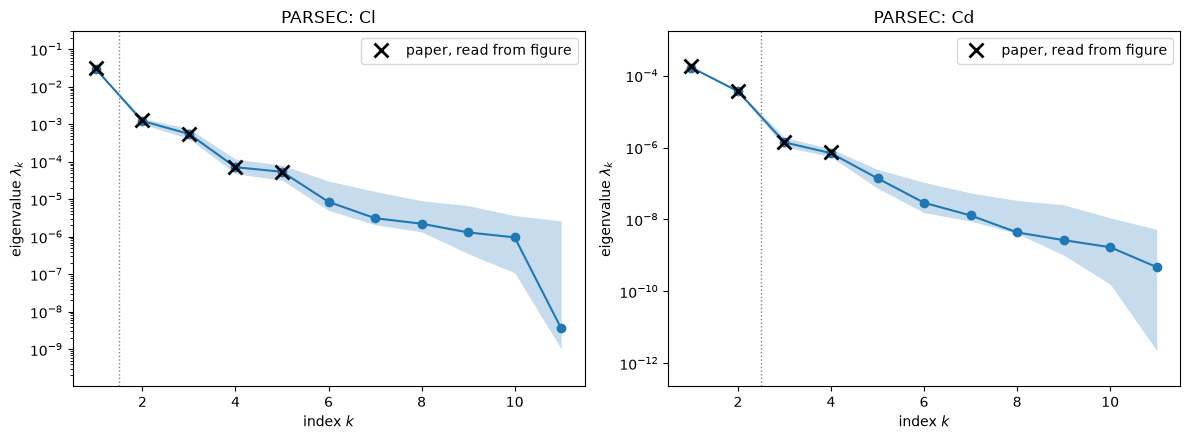

In [6]:
paper_lam = {   # read from the paper's figures (log scale)
    ('PARSEC', 'Cl'): [3.1e-2, 1.3e-3, 5.6e-4, 7.4e-5, 5.2e-5],
    ('PARSEC', 'Cd'): [1.8e-4, 3.8e-5, 1.4e-6, 7.4e-7],
    ('CST', 'Cl'): [3.5e-2, 5.0e-7, 2.4e-7],
    ('CST', 'Cd'): [4.8e-5, 3.3e-5, 1.3e-10],
}

def eig_panel(param):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, q in zip(axes, ('Cl', 'Cd')):
        ac.plotting.plot_eigenvalues(subs[(param, q)], interval='minmax', ax=ax)
        p = paper_lam[(param, q)]
        ax.plot(np.arange(1, len(p) + 1), p, 'kx', markersize=10, mew=2, label='paper, read from figure')
        ax.set_title(f'{param}: {q}')
        ax.legend()
    fig.tight_layout()
    plt.close(fig)
    for q in ('Cl', 'Cd'):
        band = ac.bootstrap_interval(subs[(param, q)].bootstrap_eigenvalues, kind='minmax')
        print(f'{param} {q} bootstrap ranges: ' + '; '.join(
            f'lambda_{k + 1} [{band[0, k]:.3g}, {band[1, k]:.3g}]' for k in range(3)))
    return fig

eig_panel('PARSEC')

**Lift** has one dominant eigenvalue: $\lambda_1 = 2.97\times10^{-2}$ and $\lambda_2 = 1.22\times10^{-3}$, a ratio of 24.3, while $\lambda_2/\lambda_3$ is only 2.20. The bootstrap ranges of $\lambda_1$, [0.0293, 0.0302], and $\lambda_2$, [0.00101, 0.00145], are far apart. **Drag** has its largest gap after the second eigenvalue: $\lambda_1 = 1.68\times10^{-4}$, $\lambda_2 = 3.68\times10^{-5}$ and $\lambda_3 = 1.39\times10^{-6}$, so $\lambda_1/\lambda_2 = 4.57$ and $\lambda_2/\lambda_3 = 26.4$. That is the two-dimensional subspace of the paper (p. 2008). All the eigenvalues read from Fig. 3 lie within about 10 % of ours, including $\lambda_5 = 5.41\times10^{-5}$ for lift (Fig. 3a: about $5.2\times10^{-5}$). The automatic rules disagree here: the linear-gap rule picks 1 for drag, and the log-gap rule picks 10 for lift because $\lambda_{11}$ is tiny.

PARSEC Cl: bootstrap mean subspace distance, k = 1..4: [0.0083 0.0453 0.0676 0.3489]
PARSEC Cd: bootstrap mean subspace distance, k = 1..4: [0.0074 0.0165 0.1089 0.1064]


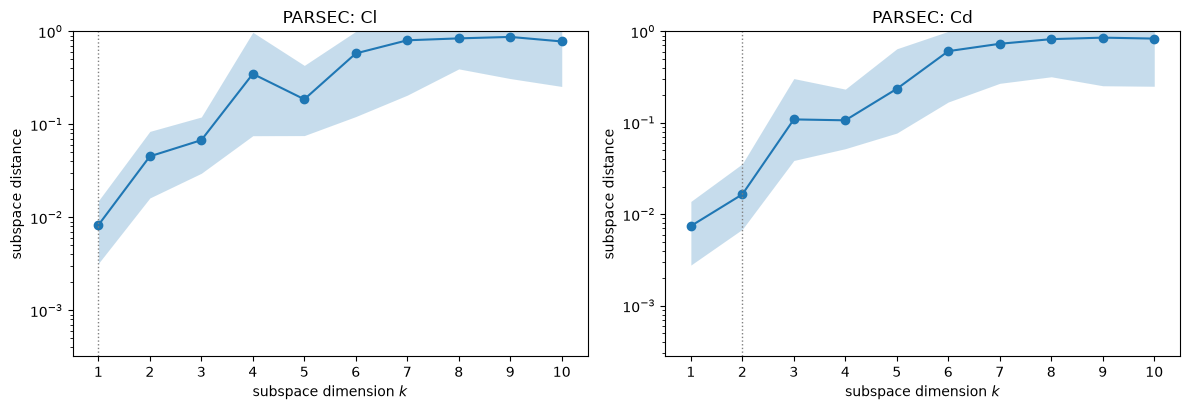

In [7]:
def err_panel(param, kmax):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, q in zip(axes, ('Cl', 'Cd')):
        ac.plotting.plot_subspace_errors(subs[(param, q)], interval='minmax', k_max=kmax, ax=ax)
        ax.set_title(f'{param}: {q}')
        print(f'{param} {q}: bootstrap mean subspace distance, k = 1..4: '
              f'{np.array2string(subs[(param, q)].bootstrap_distances.mean(axis=0)[:4], precision=4)}')
    fig.tight_layout()
    plt.close(fig)
    return fig

err_panel('PARSEC', 10)

The bootstrap subspace distances are 0.0083, 0.0453 and 0.0676 for lift at $k = 1, 2, 3$, and 0.0074, 0.0165 and 0.109 for drag. They grow where the eigenvalue gaps shrink, as in the paper's Fig. 4, which reads about 0.008, 0.045 and 0.065 for lift and 0.007, 0.017 and 0.11 for drag.

PARSEC Cl w1: +0.153 -0.091 +0.474 -0.504 +0.420 -0.541 -0.001 -0.003 -0.089 +0.113 -0.005   max |w - paper| = 0.005
PARSEC Cl w2: +0.007 +0.932 -0.069 -0.273 -0.030 +0.055 +0.006 +0.006 +0.018 +0.201 +0.087   max |w - paper| = 0.005
PARSEC Cd w1: -0.281 -0.284 +0.409 +0.795 -0.081 +0.105 -0.016 -0.027 +0.047 +0.043 -0.139   max |w - paper| = 0.005
PARSEC Cd w2: +0.203 +0.016 -0.807 +0.454 -0.189 +0.247 +0.002 +0.000 -0.035 -0.008 +0.059   max |w - paper| = 0.007


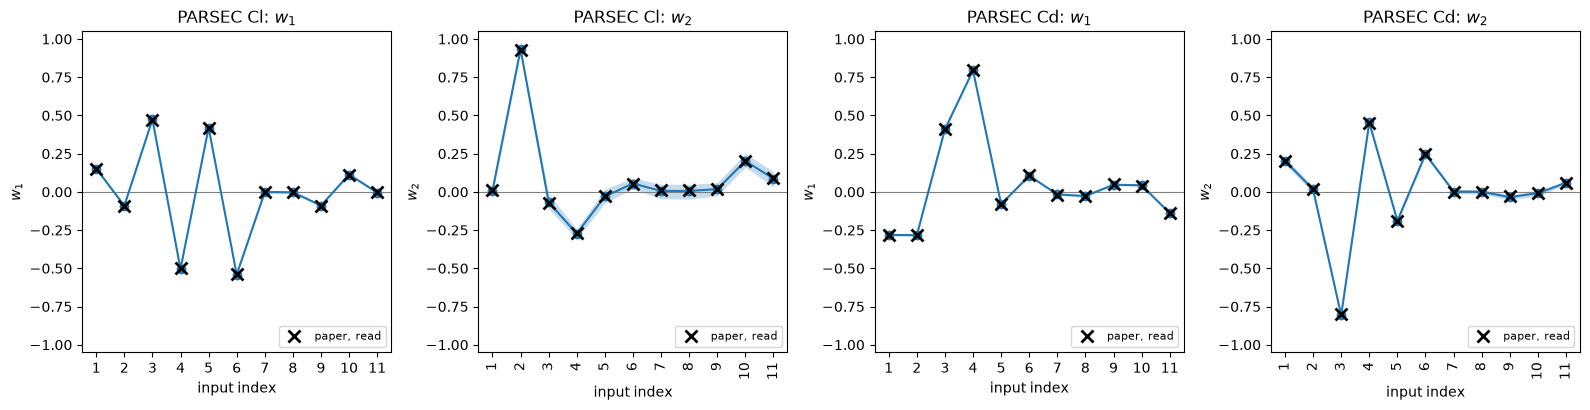

In [8]:
def vec_panel(param, labels):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    for i, q in enumerate(('Cl', 'Cd')):
        s = subs[(param, q)]
        ac.plotting.plot_eigenvectors(s, indices=[0, 1], labels=labels, interval='minmax', ax=axes[2 * i:2 * i + 2])
        P = paper_W[(param, q)]
        for j in range(P.shape[1]):
            axes[2 * i + j].plot(np.arange(1, len(labels) + 1), P[:, j], 'kx', markersize=8, mew=2,
                                 label='paper, read')
            axes[2 * i + j].legend(loc='lower right', fontsize=8)
        for j in range(2):
            axes[2 * i + j].set_title(f'{param} {q}: $w_{j + 1}$' + ('' if j < P.shape[1] else ' (not in the paper)'))
        for j in range(P.shape[1]):
            w = s.W[:, j]
            print(f'{param} {q} w{j + 1}: ' + ' '.join(f'{v:+.3f}' for v in w) +
                  f'   max |w - paper| = {np.abs(w - P[:, j]).max():.3f}')
    for ax in axes:
        ax.set_xticks(range(1, len(labels) + 1)); ax.set_xticklabels(labels); ax.tick_params(labelbottom=True)
        ax.set_xlabel('input index')
    fig.tight_layout()
    plt.close(fig)
    return fig

vec_panel('PARSEC', [str(j) for j in range(1, 12)])

Every component of the four vectors agrees with the paper's Fig. 5 to within 0.007, about the accuracy of reading the figure. The lift vector $\mathbf w_1$ is carried by the crest heights $x_3$ (+0.474) and $x_4$ (−0.504) and by the trailing-edge offset $x_5$ (+0.420) and half-thickness $x_6$ (−0.541). Moving the upper crest up and the lower crest down by equal and opposite amounts adds camber (paper p. 2009). The drag vector $\mathbf w_1$ has $x_4$ (+0.795) and $x_3$ (+0.409) with the same sign, which in the normalized coordinates thickens the section, with smaller weights on the crest positions $x_1, x_2$ (−0.281, −0.284). The second lift vector is almost the lower crest position $x_2$ (+0.932). The bands are narrow except on the second lift vector, whose eigenvalue gap is small.

PARSEC Cl: y1 in [-1.84, 1.78], y2 in [-1.41, 1.43]; corr(y1, Cl) = 0.9689
PARSEC Cd: y1 in [-1.61, 1.83], y2 in [-1.56, 1.70]; corr(y1, Cd) = 0.9327


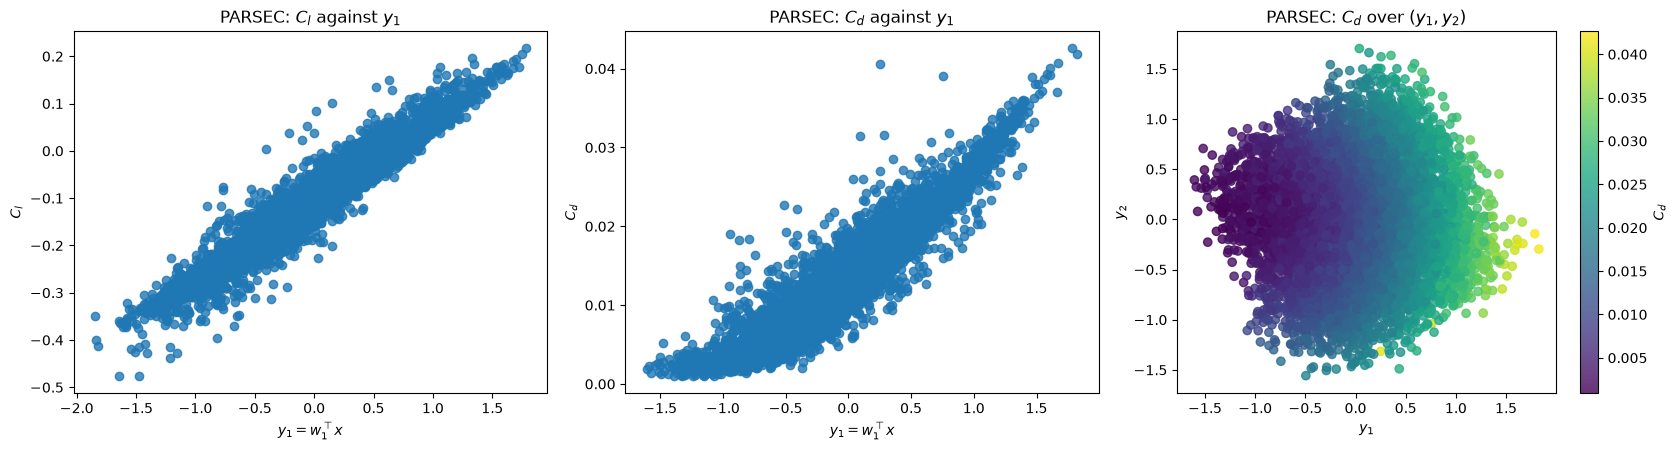

In [9]:
def summary_panel(param, X, CL, CD):
    sl, sdg = subs[(param, 'Cl')], subs[(param, 'Cd')]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    ac.plotting.plot_sufficient_summary(sl, X=X, f=CL, dims=1, qoi_label='$C_l$', ax=axes[0])
    ac.plotting.plot_sufficient_summary(sdg, X=X, f=CD, dims=1, qoi_label='$C_d$', ax=axes[1])
    ac.plotting.plot_sufficient_summary(sdg, X=X, f=CD, dims=2, qoi_label='$C_d$', ax=axes[2])
    axes[0].set_title(f'{param}: $C_l$ against $y_1$'); axes[1].set_title(f'{param}: $C_d$ against $y_1$')
    axes[2].set_title(f'{param}: $C_d$ over $(y_1, y_2)$')
    fig.tight_layout()
    plt.close(fig)
    for q, s, f in (('Cl', sl, CL), ('Cd', sdg, CD)):
        Y = X @ s.W[:, :2]                      # the inputs are already normalized
        print(f'{param} {q}: y1 in [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}], y2 in [{Y[:, 1].min():.2f}, '
              f'{Y[:, 1].max():.2f}]; corr(y1, {q}) = {np.corrcoef(Y[:, 0], f)[0, 1]:.4f}')
    return fig

summary_panel('PARSEC', Xp, CLp, CDp)

$C_l$ and $C_d$ rise steadily along their first active variables (correlations 0.9689 and 0.9327), with a wide spread at fixed $y_1$, as in the paper's Fig. 6: "strong monotonic" but "far from univariate". Lift's $y_1$ ranges over $[-1.84, 1.78]$. Over the two drag active variables (right), $C_d$ changes smoothly in both directions, the bivariate structure of the paper's Fig. 7(b).

### Results: CST

CST Cl bootstrap ranges: lambda_1 [0.0326, 0.0328]; lambda_2 [3.71e-07, 1.42e-06]; lambda_3 [1.75e-07, 9.27e-07]
CST Cd bootstrap ranges: lambda_1 [4.4e-05, 4.42e-05]; lambda_2 [3.23e-05, 3.27e-05]; lambda_3 [1.46e-10, 6.95e-10]


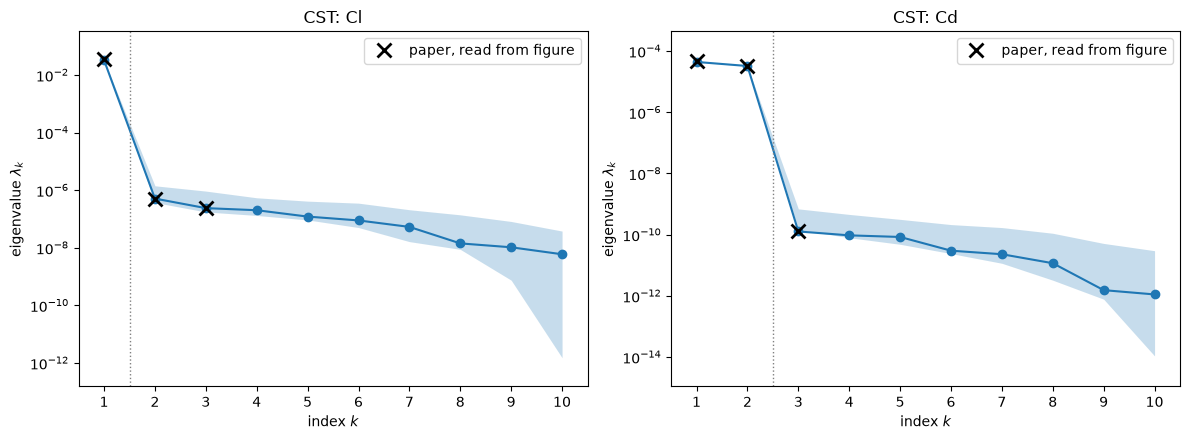

In [10]:
eig_panel('CST')

The gaps are much larger than with PARSEC, as the paper says (p. 2010). Lift: $\lambda_1 = 3.27\times10^{-2}$ and $\lambda_2 = 5.09\times10^{-7}$, a ratio of $6.43\times10^4$. Drag: $\lambda_1 = 4.41\times10^{-5}$ and $\lambda_2 = 3.25\times10^{-5}$, then $\lambda_3 = 1.27\times10^{-10}$, so $\lambda_2/\lambda_3 = 2.55\times10^5$. The paper's Fig. 8, read as $3.5\times10^{-2}$ and $5.0\times10^{-7}$ for lift and $4.8\times10^{-5}$, $3.3\times10^{-5}$ and $1.3\times10^{-10}$ for drag, agrees to within about 10 %. Here both automatic rules pick 1 for lift and 2 for drag.

CST Cl: bootstrap mean subspace distance, k = 1..4: [0.0013 0.5381 0.8102 0.8351]
CST Cd: bootstrap mean subspace distance, k = 1..4: [0.0028 0.0015 0.8057 0.8924]


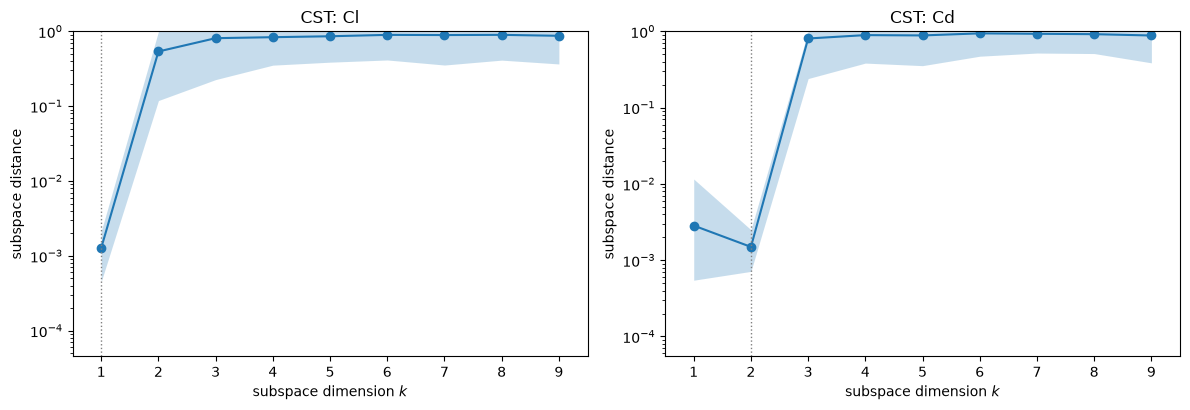

In [11]:
err_panel('CST', 9)

The one-dimensional lift subspace has a bootstrap distance of 0.0013, and the drag subspaces 0.0028 ($k = 1$) and 0.0015 ($k = 2$). The paper's Fig. 9 reads about $1.3\times10^{-3}$, $3\times10^{-3}$ and $1.6\times10^{-3}$. The distances for larger $k$ (0.538 and up for lift, 0.806 and up for drag) only show that the trailing eigenvectors are noise. For the same reason the library warns that the bootstrap replicates of the second lift vector are poorly aligned.

CST Cl w1: +0.707 -0.001 -0.000 +0.000 +0.000 -0.707 -0.001 -0.000 +0.000 -0.001   max |w - paper| = 0.001
CST Cd w1: +0.707 -0.000 +0.000 -0.000 +0.000 +0.707 +0.000 +0.000 -0.000 -0.000   max |w - paper| = 0.000
CST Cd w2: +0.707 -0.001 -0.001 +0.001 +0.001 -0.707 +0.000 -0.000 -0.001 -0.000   max |w - paper| = 0.001
CST Cl: quadratic R^2 in all ten inputs 0.998765; in x1 and x6 only 0.998751; share of |w|^2 on x1, x6: w1 0.999998
CST Cd: quadratic R^2 in all ten inputs 0.999304; in x1 and x6 only 0.999298; share of |w|^2 on x1, x6: w1 1.000000, w2 0.999998
CST quadratic in (x1, x6): Cl coefficients of x1, x6: -0.12787, +0.12796; Cd: 0.004282, 0.004289 (squares 0.003644, 0.003640); Cl at x1 = x6 = 0: -5.4e-05
CST runs with x1 = x6 (to within 0.02): 125, mean |Cl| = 0.0035 (sd of Cl over all runs 0.1053)
CST runs with x1 = -x6 (to within 0.02): 124, mean |Cl| = 0.1253 (sd of Cl over all runs 0.1053)


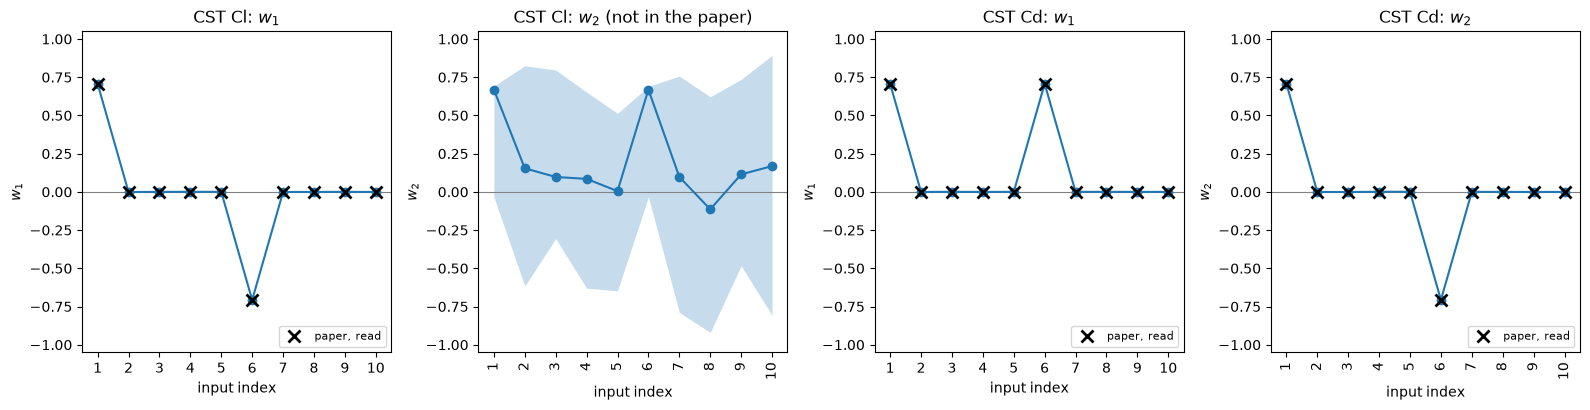

In [12]:
vec_panel_cst = vec_panel('CST', [str(j) for j in range(1, 11)])
q2 = lambda X: quad_basis(X)
for q, f in (('Cl', CLc), ('Cd', CDc)):
    print(f'CST {q}: quadratic R^2 in all ten inputs {lsq_r2(q2(Xc), f):.6f}; in x1 and x6 only '
          f'{lsq_r2(q2(Xc[:, [0, 5]]), f):.6f}; share of |w|^2 on x1, x6: ' +
          ', '.join(f'w{j + 1} {np.sum(subs[("CST", q)].W[[0, 5], j] ** 2):.6f}' for j in range(subs[('CST', q)].n)))
c_sym = np.linalg.lstsq(q2(Xc[:, [0, 5]]), np.c_[CLc, CDc], rcond=None)[0]     # basis 1, x1, x6, x1^2, x1 x6, x6^2
print(f'CST quadratic in (x1, x6): Cl coefficients of x1, x6: {c_sym[1, 0]:+.5f}, {c_sym[2, 0]:+.5f}; '
      f'Cd: {c_sym[1, 1]:.6f}, {c_sym[2, 1]:.6f} (squares {c_sym[3, 1]:.6f}, {c_sym[5, 1]:.6f}); Cl at x1 = x6 = 0: {c_sym[0, 0]:+.1e}')
for lab, msk in (('x1 = x6', np.abs(Xc[:, 0] - Xc[:, 5]) < 0.02), ('x1 = -x6', np.abs(Xc[:, 0] + Xc[:, 5]) < 0.02)):
    print(f'CST runs with {lab} (to within 0.02): {msk.sum()}, mean |Cl| = {np.abs(CLc[msk]).mean():.4f} (sd of Cl over all runs {CLc.std():.4f})')
vec_panel_cst

All three vectors are $(\pm\mathbf e_1 \pm \mathbf e_6)/\sqrt2$ to three digits (lift $\mathbf w_1$: +0.707 on $x_1$, −0.707 on $x_6$), as in the paper's Fig. 10. The share of $\lVert\mathbf w\rVert^2$ on $x_1$ and $x_6$ is at least 0.999998. A direct test agrees: a quadratic in $x_1$ and $x_6$ alone has $R^2$ = 0.998751 for $C_l$ and 0.999298 for $C_d$, against 0.998765 and 0.999304 with all ten inputs. So in these runs **the eight other CST inputs have no effect**, which the paper reports (p. 2011). This is a property of the 2016 code that made the runs, not of the CST parameterization in general: in the authors' later CST study (Bernstein coefficients, posted in the same repository) all ten coefficients carry weight in the lift vector. Table 3's nominal values of ±1 for $x_2$–$x_5$ and $x_7$–$x_{10}$ are not Eq. (13) coefficients of a NACA 0012 fit, which are about (0.170, −0.059, 0.063, −0.085, 0.057), and we cannot tell from the posted files how those inputs entered the shape (`DATA.md`).

CST Cl: y1 in [-1.38, 1.40], y2 in [-1.65, 1.66]; corr(y1, Cl) = -0.9994
CST Cd: y1 in [-1.40, 1.39], y2 in [-1.38, 1.40]; corr(y1, Cd) = 0.8929


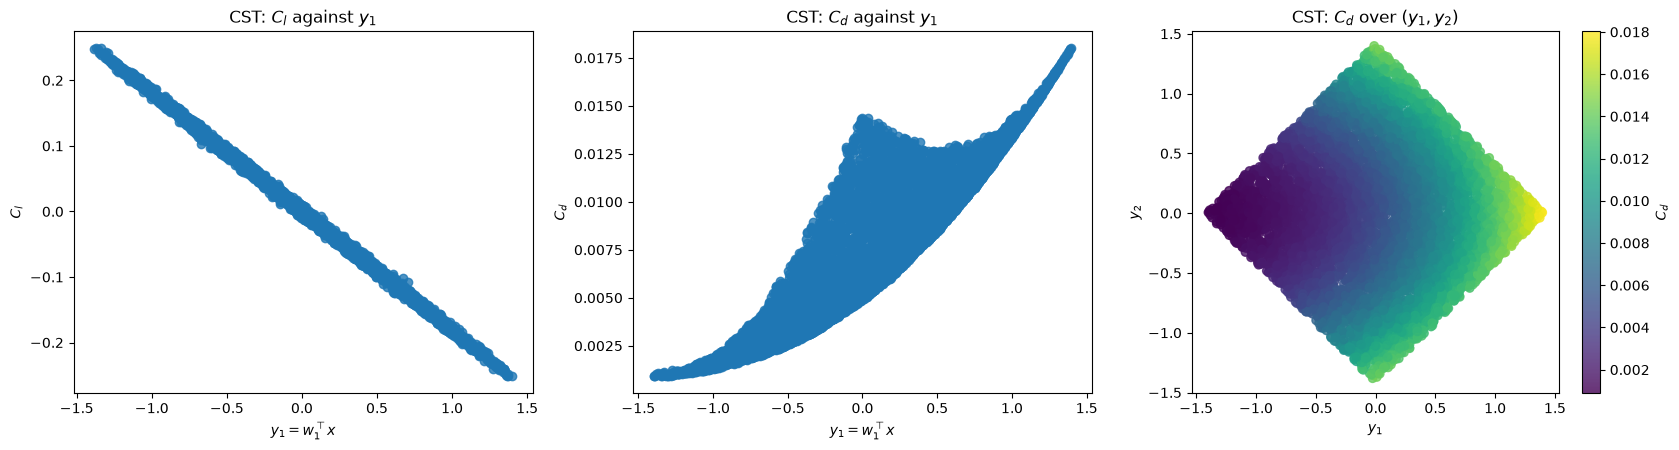

In [13]:
summary_panel('CST', Xc, CLc, CDc)

Lift is almost exactly linear in its one active variable: the correlation is −0.9994 over $y_1\in[-1.38, 1.40]$, with $C_l$ from about 0.25 down to −0.25, as in the paper's Fig. 11(a). Lift *decreases* along $+\mathbf w_1$, that is, as $x_1$ rises and $x_6$ falls in the normalized coordinates. The runs are mirror-symmetric in $x_1$ and $x_6$ (printed with the eigenvectors): the $C_l$ coefficients of $x_1$ and $x_6$ in a quadratic are −0.12787 and +0.12796, the $C_d$ coefficients 0.004282 and 0.004289, and the 125 runs with $x_1 \approx x_6$ have mean $|C_l|$ = 0.0035, against 0.1253 for the 124 with $x_1 \approx -x_6$. So $x_1 = x_6$ gives a symmetric section (with zero lift, as it must at 0°), and both leading coefficients grow in magnitude with $x$, as the 0.8–1.2 × nominal rule of the authors' scripts says. Along $+\mathbf w_1$ the surface of column 1 then bulges more and that of column 6 less, and lift falls. With the paper's labels (column 1 upper, p. 2011) that means less lift for more positive camber. The authors' later CST study at the same flow conditions shows the usual behaviour, with columns 1–5 on the lower surface as their 2019 sampling script states, so the more likely reading is that the 2016 code also had $x_1$ on the lower surface. The posted files cannot prove this (`DATA.md`, "Physical values"). Drag is not a function of $y_1$ alone (middle; correlation 0.8929). Over $(y_1, y_2)$, where the data fill a square rotated by 45° because only $x_1$ and $x_6$ matter, it is a smooth bowl with its minimum at the left corner, the paper's Fig. 11(b).

#### Lift and drag share a direction

The paper notes that the CST lift direction equals the second drag direction (p. 2011), so the lift varies along the drag active subspace (its Fig. 13). The cell measures, for both parameterizations, the cosine between the lift vector $\mathbf w_1^{C_l}$ and each drag vector, and the distance from $\mathbf w_1^{C_l}$ to the two-dimensional drag subspace, $\lVert(\mathbf I - \mathbf W_1^{C_d}\mathbf W_1^{C_d\,T})\,\mathbf w_1^{C_l}\rVert$. It also plots $C_l$ over the drag active variables.

PARSEC: w1(Cl).w1(Cd) = -0.3134, w1(Cl).w2(Cd) = -0.7928; distance of w1(Cl) from the Cd subspace = 0.5227 (angle 31.5 deg)
CST: w1(Cl).w1(Cd) = -0.0008, w1(Cl).w2(Cd) = +1.0000; distance of w1(Cl) from the Cd subspace = 0.0015 (angle 0.1 deg)


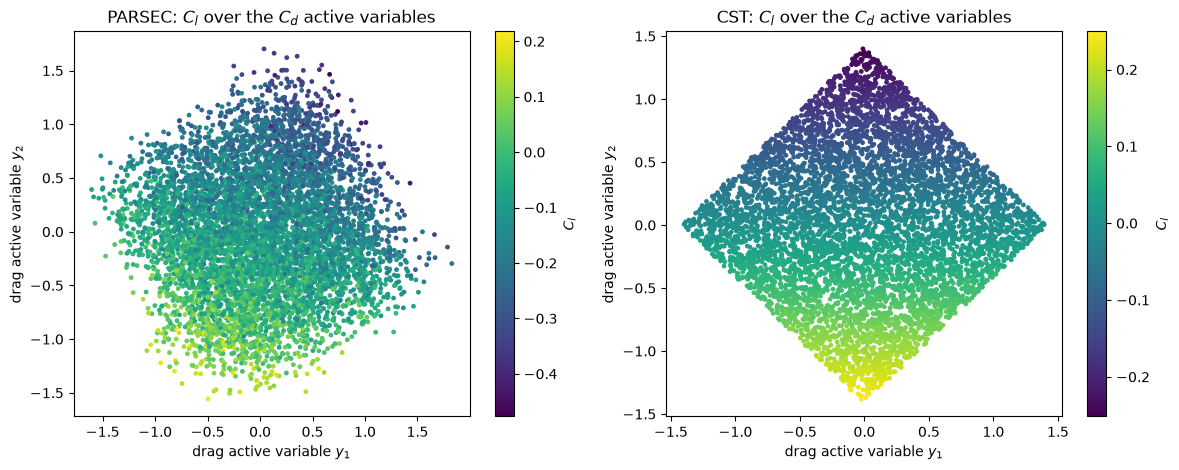

In [14]:
for param, X, CL in (('PARSEC', Xp, CLp), ('CST', Xc, CLc)):
    wl = subs[(param, 'Cl')].W[:, 0]
    Wd = subs[(param, 'Cd')].W[:, :2]
    print(f'{param}: w1(Cl).w1(Cd) = {wl @ Wd[:, 0]:+.4f}, w1(Cl).w2(Cd) = {wl @ Wd[:, 1]:+.4f}; '
          f'distance of w1(Cl) from the Cd subspace = {np.linalg.norm(wl - Wd @ (Wd.T @ wl)):.4f} '
          f'(angle {np.degrees(np.arcsin(min(1.0, np.linalg.norm(wl - Wd @ (Wd.T @ wl))))):.1f} deg)')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (param, X, CL) in zip(axes, (('PARSEC', Xp, CLp), ('CST', Xc, CLc))):
    Y = X @ subs[(param, 'Cd')].W[:, :2]
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=CL, s=6, cmap='viridis')
    fig.colorbar(sc, ax=ax, label='$C_l$')
    ax.set_xlabel('drag active variable $y_1$'); ax.set_ylabel('drag active variable $y_2$')
    ax.set_title(f'{param}: $C_l$ over the $C_d$ active variables')
fig.tight_layout()
plt.close(fig)
fig

Under CST the lift vector is the second drag vector to four digits ($\mathbf w_1^{C_l}\cdot\mathbf w_2^{C_d} = +1.0000$). Its distance from the drag subspace is 0.0015, so $C_l$ varies along $y_2$ of drag only (right panel), the paper's Fig. 13 and the basis of its Pareto-front argument. Under PARSEC the lift vector is 31.5° out of the drag plane (distance 0.5227; cosines −0.3134 and −0.7928 with the two drag vectors). The paper makes the "identical" claim for CST only, and the data confirm that the claim does not carry over to PARSEC.

#### Convergence with the number of runs (the paper's Fig. 12)

The paper draws $k$ runs with replacement from all runs, re-estimates the subspace, and measures the distance $\lVert\hat{\mathbf W}_1^T\mathbf W_2^{(k)}\rVert_2$ to the subspace from all runs. It does this for $k = 100, 200, \dots, 6400$, with the one-dimensional lift and two-dimensional drag subspaces (Sec. IV.C; `sub_conv.m` in the authors' repository). We repeat it with 100 draws per size, where the paper used 500. The bands are the ranges over the draws, the black crosses the paper's means at $N = 100$ and 6400, read from Fig. 12. The cell also counts the library's rank-deficient-fit warnings (the smallest draws are close to the 78 coefficients of the PARSEC quadratic).

2800 fits in 24.2 s; rank-deficient-fit warnings: 0
CST Cl: mean distance 100: 0.02, 200: 0.00909, 400: 0.00576, 800: 0.00399, 1600: 0.00262, 3200: 0.00191, 6400: 0.00132; slope -0.62
PARSEC Cl: mean distance 100: 0.163, 200: 0.0626, 400: 0.0377, 800: 0.0251, 1600: 0.0174, 3200: 0.012, 6400: 0.00844; slope -0.67
CST Cd: mean distance 100: 0.0203, 200: 0.00981, 400: 0.00676, 800: 0.00439, 1600: 0.00301, 3200: 0.00221, 6400: 0.00148; slope -0.60
PARSEC Cd: mean distance 100: 0.297, 200: 0.115, 400: 0.0674, 800: 0.0492, 1600: 0.0333, 3200: 0.0237, 6400: 0.0163; slope -0.65


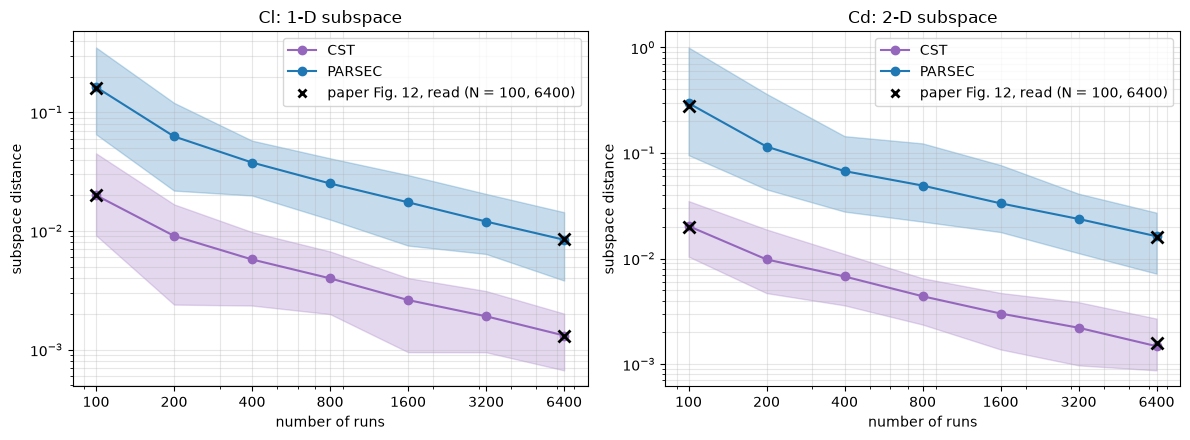

In [15]:
sizes = 100 * 2 ** np.arange(7)
reps = 100
rng = np.random.default_rng(SEED)
conv, n_rankdef = {}, 0
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    for key, (sp, X, f) in cases.items():
        n = 1 if key[1] == 'Cl' else 2
        W1 = subs[key].W[:, :n]
        E = np.zeros((len(sizes), reps))
        for i, k in enumerate(sizes):
            for r in range(reps):
                idx = rng.integers(0, len(f), k)
                s = ac.active_subspace(space=sp, X=X[idx], f=f[idx], estimator='qphd', n=n)
                E[i, r] = np.linalg.norm(W1.T @ s.W[:, n:], 2)
        conv[key] = E
n_rankdef = sum('rank' in str(w.message).lower() for w in caught)
print(f'{len(cases) * len(sizes) * reps} fits in {time.perf_counter() - t0:.1f} s; rank-deficient-fit warnings: {n_rankdef}')
paper_conv = {('PARSEC', 'Cl'): (0.16, 8.5e-3), ('CST', 'Cl'): (2.0e-2, 1.3e-3),
              ('PARSEC', 'Cd'): (0.28, 1.6e-2), ('CST', 'Cd'): (2.0e-2, 1.6e-3)}   # Fig. 12 at N = 100, 6400, read
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, q in zip(axes, ('Cl', 'Cd')):
    for param, col in (('CST', 'C4'), ('PARSEC', 'C0')):
        E = conv[(param, q)]
        ax.fill_between(sizes, E.min(axis=1), E.max(axis=1), color=col, alpha=0.25)
        ax.loglog(sizes, E.mean(axis=1), 'o-', color=col, label=param)
        ax.loglog([100, 6400], paper_conv[(param, q)], 'x', color='k', markersize=9, mew=2)
        print(f'{param} {q}: mean distance ' + ', '.join(f'{k}: {e:.3g}' for k, e in zip(sizes, E.mean(axis=1))) +
              f'; slope {np.polyfit(np.log(sizes), np.log(E.mean(axis=1)), 1)[0]:.2f}')
    ax.plot([], [], 'kx', mew=2, label='paper Fig. 12, read (N = 100, 6400)')
    ax.set_xticks(sizes); ax.set_xticklabels(sizes)
    ax.set_xlabel('number of runs'); ax.set_ylabel('subspace distance')
    ax.set_title(f'{q}: {"1" if q == "Cl" else "2"}-D subspace'); ax.legend(); ax.grid(True, which='both', alpha=0.3)
fig.tight_layout()
plt.close(fig)
fig

The mean distances at $N = 6400$ are 0.00132 (CST lift), 0.00844 (PARSEC lift), 0.00148 (CST drag) and 0.0163 (PARSEC drag). At $N = 100$ they are 0.0200, 0.163, 0.0203 and 0.297. The paper's Fig. 12 reads $1.3\times10^{-3}$, $8.5\times10^{-3}$, $1.6\times10^{-3}$ and $1.6\times10^{-2}$ at 6400, and $2.0\times10^{-2}$, 0.16, $2.0\times10^{-2}$ and 0.28 at 100, which matches ours. CST is 6.4 (lift) and 11 (drag) times more accurate than PARSEC at $N = 6400$, as the paper concludes. The fitted log–log slopes are −0.60 to −0.67, a little steeper than the $1/\sqrt N$ the paper describes. Part of the reason is that at $k = 6400$ the draws reuse most of the runs that define the reference subspace. No fit was rank deficient.

#### Sensitivity: the PARSEC 500-design set

The check after loading showed that the PARSEC 500-design set does not follow the same input–output map as the other two sets. **Rule for this check only:** drop the rows with `sample_set == 500` and re-estimate (no bootstrap).

In [16]:
keep = set_p != 500
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for q, f in (('Cl', CLp), ('Cd', CDp)):
        s = ac.active_subspace(space=space_p, X=Xp[keep], f=f[keep], estimator='qphd', n=2)
        full = subs[('PARSEC', q)]
        lam, lam0 = s.eigenvalues, full.eigenvalues
        cos = [abs(s.W[:, j] @ full.W[:, j]) for j in range(2)]
        print(f'PARSEC {q}, {keep.sum()} runs: lambda_1..3 = ' + ', '.join(f'{v:.3e}' for v in lam[:3]) +
              ' (all runs: ' + ', '.join(f'{v:.3e}' for v in lam0[:3]) + f'); |w1.w1| = {cos[0]:.5f}, |w2.w2| = {cos[1]:.5f}; '
              f'ratios {lam[0] / lam[1]:.3g}, {lam[1] / lam[2]:.3g}')

PARSEC Cl, 5975 runs: lambda_1..3 = 2.972e-02, 1.287e-03, 6.039e-04 (all runs: 2.970e-02, 1.223e-03, 5.552e-04); |w1.w1| = 0.99994, |w2.w2| = 0.99989; ratios 23.1, 2.13
PARSEC Cd, 5975 runs: lambda_1..3 = 1.711e-04, 3.591e-05, 6.474e-07 (all runs: 1.681e-04, 3.676e-05, 1.391e-06); |w1.w1| = 0.99996, |w2.w2| = 0.99985; ratios 4.76, 55.5


Without the 500-design set (5975 runs), the directions do not change: $|\mathbf w_1\cdot\mathbf w_1| = 0.99994$ (lift) and 0.99996 (drag), and $|\mathbf w_2\cdot\mathbf w_2| \ge 0.99985$. The leading eigenvalues change by less than 6 %. The small ones drop: drag $\lambda_3$ falls from $1.39\times10^{-6}$ to $6.47\times10^{-7}$, so its gap $\lambda_2/\lambda_3$ grows from 26.4 to 55.5, and lift $\lambda_2/\lambda_3$ goes from 2.20 to 2.13. The 500 set adds scatter that the quadratic absorbs into the trailing eigenvalues. It does not move the subspaces.

#### Surrogates

Leave-one-out $R^2$ of polynomials in the active variables, compared with the full quadratic in all inputs (the model behind the estimator). The paper fits no surrogate for accuracy; it uses quadratics in the active variables for the drag contours of Fig. 11(b) and Fig. 13.

In [17]:
loo = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for param, sp, X, CL, CD in (('PARSEC', space_p, Xp, CLp, CDp), ('CST', space_c, Xc, CLc, CDc)):
        sl, sdg = subs[(param, 'Cl')], subs[(param, 'Cd')]
        for label, q, s, f, deg in (('Cl, 1-D cubic', 'Cl', sl, CL, 3), ('Cl, all-input quadratic', 'Cl', None, CL, 2),
                                    ('Cd, 1-D cubic', 'Cd', ac.with_dimension(sdg, 1), CD, 3),
                                    ('Cd, 2-D quadratic', 'Cd', sdg, CD, 2), ('Cd, 2-D cubic', 'Cd', sdg, CD, 3),
                                    ('Cd, all-input quadratic', 'Cd', None, CD, 2)):
            g = ac.fit_surrogate(X=X, f=f, space=sp, subspace=s, kind='poly', degree=deg)
            loo[(param, label)] = g.loo_r_squared
            print(f'{param:6s} {label:24s} LOO R^2 = {g.loo_r_squared:.5f}')

PARSEC Cl, 1-D cubic            LOO R^2 = 0.93881
PARSEC Cl, all-input quadratic  LOO R^2 = 0.95772
PARSEC Cd, 1-D cubic            LOO R^2 = 0.89832
PARSEC Cd, 2-D quadratic        LOO R^2 = 0.96984
PARSEC Cd, 2-D cubic            LOO R^2 = 0.97124
PARSEC Cd, all-input quadratic  LOO R^2 = 0.97449
CST    Cl, 1-D cubic            LOO R^2 = 0.99875
CST    Cl, all-input quadratic  LOO R^2 = 0.99874
CST    Cd, 1-D cubic            LOO R^2 = 0.79762
CST    Cd, 2-D quadratic        LOO R^2 = 0.99930


CST    Cd, 2-D cubic            LOO R^2 = 0.99950
CST    Cd, all-input quadratic  LOO R^2 = 0.99929


Lift is well approximated by a cubic in one active variable: the leave-one-out $R^2$ is 0.99875 for CST, and 0.93881 for PARSEC, against 0.95772 for the full 78-term PARSEC quadratic. Drag needs two active variables. A quadratic in $(y_1, y_2)$ gives 0.96984 (PARSEC) and 0.99930 (CST), against 0.89832 and 0.79762 for a 1-D cubic, and the full quadratics reach 0.97449 and 0.99929. So for CST the 2-D quadratic loses nothing against the 66-term quadratic. For PARSEC, the active variables give up 0.019 ($C_l$) and 0.005 ($C_d$) of $R^2$ against the full quadratic, in exchange for one or two variables instead of eleven.

### Comparison with the paper

The paper prints no numbers for these results, only figures. Its values below were read from the log-scale or linear figures, to about 10–20 % for eigenvalues and subspace distances and about ±0.02 for eigenvector components.

In [18]:
def fmt(v): return f'{v:.2g}'
rows = [('PARSEC runs', '6500 (p. 2008)', f'{len(CLp)} (28 infeasible designs have no run)'),
        ('CST runs', '6500 (p. 2010)', f'{len(CLc)}'),
        ('angle of attack of the runs', '0 to 2.5 deg (p. 2008)', '0 deg in all 12,972 posted files')]
for key in subs:
    lam = subs[key].eigenvalues
    p = paper_lam[key]
    rows.append((f'{key[0]} {key[1]} lambda_1, lambda_2, lambda_3', ', '.join(fmt(v) for v in p[:3]),
                 ', '.join(fmt(v) for v in lam[:3])))
    rows.append((f'{key[0]} {key[1]} dimension', '1' if key[1] == 'Cl' else '2', str(subs[key].n)))
    for j in range(paper_W[key].shape[1]):
        rows.append((f'{key[0]} {key[1]} w{j + 1}: max |difference| from paper', '(read)',
                     f'{np.abs(subs[key].W[:, j] - paper_W[key][:, j]).max():.3f}'))
for key in subs:
    rows.append((f'{key[0]} {key[1]} subspace distance, N = 6400', fmt(paper_conv[key][1]),
                 fmt(conv[key][-1].mean())))
for q, p, v in rows:
    print(f'{q:52s} {p:>24s}   {v}')

PARSEC runs                                                    6500 (p. 2008)   6472 (28 infeasible designs have no run)
CST runs                                                       6500 (p. 2010)   6500
angle of attack of the runs                            0 to 2.5 deg (p. 2008)   0 deg in all 12,972 posted files
PARSEC Cl lambda_1, lambda_2, lambda_3                 0.031, 0.0013, 0.00056   0.03, 0.0012, 0.00056
PARSEC Cl dimension                                                         1   1
PARSEC Cl w1: max |difference| from paper                              (read)   0.005
PARSEC Cl w2: max |difference| from paper                              (read)   0.005
PARSEC Cd lambda_1, lambda_2, lambda_3               0.00018, 3.8e-05, 1.4e-06   0.00017, 3.7e-05, 1.4e-06
PARSEC Cd dimension                                                         2   2
PARSEC Cd w1: max |difference| from paper                              (read)   0.005
PARSEC Cd w2: max |difference| from paper         

| Quantity | Paper value | Notebook value |
|---|---|---|
| Runs | 6500 PARSEC, 6500 CST (pp. 2008, 2010) | 6472 PARSEC (28 designs failed the shape check and were not run), 6500 CST |
| Angle of attack | 0–2.5° (p. 2008) | 0° in all 12,972 posted runs |
| Design inputs | posted (`*_designs.mat`, referenced by `mixsamples.m`) | not posted; regenerated from seeds 43, 44, 45 (generator checked bit for bit against the authors' later `.mat` files) |
| Matrix of the quadratic model | $\mathbf H^2 + \mathbf v\mathbf v^T$ (Eq. 21) | $\mathbf g\mathbf g^T + \mathbf H\mathbf H/3$, which matches Figs. 3 and 8; $\mathbf H^2$ would make $\lambda_2, \lambda_3$ of lift 3 times larger |
| PARSEC $C_l$: $\lambda_1, \lambda_2, \lambda_3$ | about 0.031, 0.0013, 0.00056 (Fig. 3a, read) | 0.0297, 0.00122, 0.000555 |
| PARSEC $C_d$: $\lambda_1, \lambda_2, \lambda_3$ | about 1.8e-4, 3.8e-5, 1.4e-6 (Fig. 3b, read) | 1.68e-4, 3.68e-5, 1.39e-6 |
| PARSEC dimension | 1 (lift), 2 (drag) | 1 and 2 (ratios 24.3; 4.57 then 26.4) |
| PARSEC subspace distance, $k=1,2,3$ | lift ≈ 0.008, 0.045, 0.065; drag ≈ 0.007, 0.017, 0.11 (Fig. 4, read) | lift 0.0083, 0.0453, 0.0676; drag 0.0074, 0.0165, 0.109 |
| PARSEC eigenvectors | Fig. 5 | every component within 0.007 of the figure |
| CST $C_l$: $\lambda_1, \lambda_2$ | about 3.5e-2, 5.0e-7 (Fig. 8a, read) | 3.27e-2, 5.09e-7 |
| CST $C_d$: $\lambda_1, \lambda_2, \lambda_3$ | about 4.8e-5, 3.3e-5, 1.3e-10 (Fig. 8b, read) | 4.41e-5, 3.25e-5, 1.27e-10 |
| CST subspace distance | lift ≈ 1.3e-3; drag ≈ 3e-3, 1.6e-3 (Fig. 9, read) | lift 0.0013; drag 0.0028, 0.0015 |
| CST eigenvectors | only $x_1$, $x_6$ nonzero, ±0.71 (Fig. 10) | ±0.707 on $x_1$, $x_6$; share of $\lVert\mathbf w\rVert^2$ ≥ 0.999998 |
| CST lift vector vs second drag vector | "identical" (p. 2011) | $\mathbf w_1^{C_l}\cdot\mathbf w_2^{C_d} = 1.0000$ |
| PARSEC lift vector vs drag plane | not reported | 31.5° out of the plane |
| Subspace distance at $N = 6400$ (Fig. 12) | PARSEC 8.5e-3 / 1.6e-2, CST 1.3e-3 / 1.6e-3 (lift / drag, read) | PARSEC 0.0084 / 0.0163, CST 0.0013 / 0.0015 |
| Convergence rate | "approximately $1/\sqrt N$" | slopes −0.60 to −0.67 |
| Surrogate LOO $R^2$ | not reported | lift 1-D cubic: CST 0.99875, PARSEC 0.93881; drag 2-D quadratic: CST 0.99930, PARSEC 0.96984 |

### References

[1] Z. J. Grey and P. G. Constantine. [Active subspaces of airfoil shape parameterizations](https://doi.org/10.2514/1.J056054). *AIAA Journal*, 56(5):2003–2017, 2018. Data: [zgrey/ASAP](https://github.com/zgrey/ASAP).

[2] H. Sobieczky. [Parametric airfoils and wings](https://doi.org/10.1007/978-3-322-89952-1_4). In K. Fujii and G. S. Dulikravich (eds.), *Recent Development of Aerodynamic Design Methodologies*, Notes on Numerical Fluid Mechanics 65, pp. 71–87, Vieweg+Teubner, 1999.

[3] B. M. Kulfan. [Universal parametric geometry representation method](https://doi.org/10.2514/1.29958). *Journal of Aircraft*, 45(1):142–158, 2008.

[4] T. D. Economon, F. Palacios, S. R. Copeland, T. W. Lukaczyk, and J. J. Alonso. [SU2: an open-source suite for multiphysics simulation and design](https://doi.org/10.2514/1.J053813). *AIAA Journal*, 54(3):828–846, 2016.

[5] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[6] K.-C. Li. [On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma](https://doi.org/10.1080/01621459.1992.10476258). *Journal of the American Statistical Association*, 87(420):1025–1039, 1992.

[R1]: https://doi.org/10.2514/1.J056054
[R2]: https://doi.org/10.1007/978-3-322-89952-1_4
[R3]: https://doi.org/10.2514/1.29958
[R4]: https://doi.org/10.2514/1.J053813

In [19]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 97.8 s
